# 地形精细化插值

把模式粗网格上的近地面要素订正到细网格或站点。当前业务入口是 `cli/orographic_nwp_3d_downscaling_cli.py` 的 `process`。

## 算法实现原理

目标点落在源格点的四个角之间。每个角先按高度差修正，再做双线性插值：

修正量 = (目标海拔 − 源格点海拔) × 垂直变率 × eta

eta 为 1 时用满垂直变率。求参时在 0.1 到 1.0、步长 0.1 上选取与实况最接近的 eta。风速结果小于 0 记为 0，相对湿度限制在 0 到 100，气压低于 200 记为 200。

公式在 `src/fast_refine_interp_util_plugin.py` 的 `dem_interp_scalar`。`Class_Interp_dem.dDEM_3d_interp_scalar` 调用这一份。源程序没有附参考文献。

`process` 的顺序是：读配置、地形和目标点；`SpatialInterpPlugin` 按时效插值；把格点产品写成 NetCDF；需要时再做 `MaxMinPlugin`、`TimeInterpPlugin`；`operation` 含 `p` 时由 `BestEtaPlugin` 算出 eta，再写成 `{时效}_{要素}_eta.h5`。

## 算法参数说明

| 参数 | 预设 | 含义 |
| --- | --- | --- |
| `operation` | `i` | `i` 插值，`p` 求参，`ip` 两者 |
| `begin_date` | 运行时刻 | 北京时业务时间，`YYYYMMDDHH` |
| `resolution` | `5km` | `site`、`1km` 或 `5km` |
| `model_region` | `EC_12P5KM` | 模式区域 |
| `para_file` | `Fast_refine_interp_5km.ini` | 要素、时效和开关，放在 `work_dir` |
| `work_dir` | 本包 `resource` | 参数文件所在目录 |
| `root_path` | 本包目录 | 项目根 |
| `pro_count` | `1` | 大于 1 时打开时效并行，并作为进程数 |
| `update` | `0` | `1` 表示已有结果也重算 |
| `debug` | `0` | 大于等于 1 时打印耗时 |
| `s3_method` | `g_interp` | 结果目录中的方法名 |
| `site_name` | `Station1` | 站点文件名 |

要素、时效范围和 NetCDF 开关在 `resource/Fast_refine_interp_5km.ini`，不在 `resource/conf.ini`。

## 算法调用示例

在本包目录：

```bash
python -m cli begin_date=2026111813 operation=i debug=1 update=1
```

在 `00temp`：

```bash
python -m orographic_nwp_3d_downscaling begin_date=2026111813 operation=i debug=1 update=1
```

```python
from cli.orographic_nwp_3d_downscaling_cli import process

process(begin_date="2026111813", operation="i", debug=1, update=1)
```

下面先用公式画出一座山对 2 米气温的订正。完整业务计算放在最后，默认不启动。


山顶附近最低气温 12.20


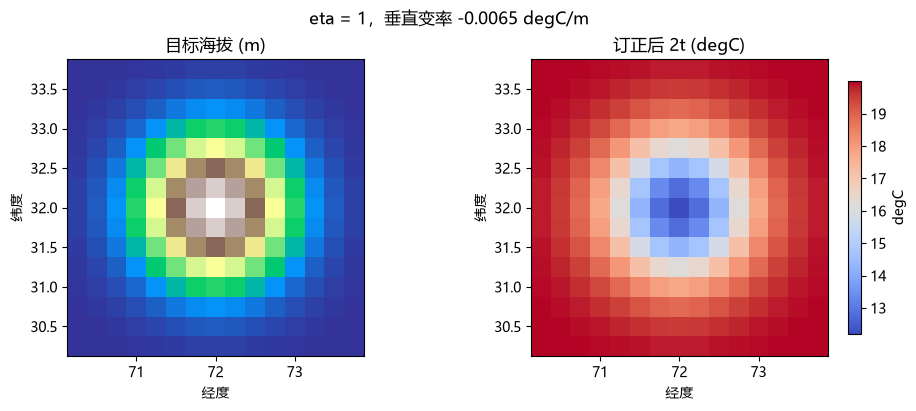

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager

root = Path.cwd().resolve()
if root.name == "nbs":
    root = root.parent
src = root / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))
from fast_refine_interp_util_plugin import dem_interp_scalar

font = Path(r"C:\Windows\Fonts\msyh.ttc")
if font.is_file():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

lon = np.arange(70.0, 75.0, 1.0)
lat = np.arange(30.0, 35.0, 1.0)
grid_lon, grid_lat = np.meshgrid(lon, lat)
source = {
    "begin_lon": float(lon[0]),
    "begin_lat": float(lat[0]),
    "lon_res": 1.0,
    "lat_res": 1.0,
    "Nlon": int(lon.size),
    "Nlat": int(lat.size),
    "ndy2d_x_lon": grid_lon,
    "ndy2d_y_lat": grid_lat,
    "alt": np.zeros(grid_lon.shape),
    "2t": np.full(grid_lon.shape, 20.0),
}
fine_lon = np.arange(70.25, 73.76, 0.25)
fine_lat = np.arange(30.25, 33.76, 0.25)
fine_x, fine_y = np.meshgrid(fine_lon, fine_lat)
hill = 1200.0 * np.exp(-((fine_x - 72.0) ** 2 + (fine_y - 32.0) ** 2) / 0.8)
target = {"lon": fine_x, "lat": fine_y, "alt": hill}
lapse = np.full(grid_lon.shape, -0.0065)
corrected = dem_interp_scalar(target, source, lapse, eta=1.0, skey="2t")
print("山顶附近最低气温 %.2f" % float(np.nanmin(corrected)))

fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.0), constrained_layout=True)
axes[0].pcolormesh(fine_x, fine_y, hill, cmap="terrain", shading="auto")
axes[0].set_title("目标海拔 (m)")
mesh = axes[1].pcolormesh(fine_x, fine_y, corrected, cmap="coolwarm", shading="auto")
axes[1].set_title("订正后 2t (degC)")
for ax in axes:
    ax.set_xlabel("经度")
    ax.set_ylabel("纬度")
    ax.set_aspect("equal", adjustable="box")
fig.colorbar(mesh, ax=axes[1], shrink=0.85, label="degC")
fig.suptitle("eta = 1，垂直变率 -0.0065 degC/m")
plt.show()


In [2]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
if root.name == "nbs":
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from cli.orographic_nwp_3d_downscaling_cli import process

RUN = False
if RUN:
    process(
        begin_date="2026111813",
        operation="i",
        resolution="5km",
        model_region="EC_12P5KM",
        debug=1,
        update=1,
    )
